# Addis FTIR EC on all 246 public SPARTAN filters (20 Oct 2026)

On 19 Oct Ann asked that work after the AAAR 2026 poster use all available QC'd Addis data. The poster keeps the
**189** filters that have a deployed SPARTAN FTIR EC in our in-house feed (233 in the meeting evaluation set), so that
every panel is on the same filters. The public SPARTAN release **v3.1.4** has **246** ETAD (Addis Ababa) filters with both
FTIR EC (method 218) and HIPS BC (method 221), sampled 2022-12-07 to 2026-03-01. This notebook reruns the poster's
spline-baseline calibrations on those 246 filters and compares old against new.

* **Workflow:** `workflows/run_addis_public246_20261020.py` → `output/tables/addis_public246_20261020/` (fits about 15 s,
  explorer grid about 20 min, local). It reuses `analog_bias.fit_cohort` / `correlation_analogs` and the explorer
  grid's own `configs()`, so the code path is the one that produced the poster.
* **Spectra:** no new baseline correction was needed. The frozen Colab run the poster uses
  (`vibes_colab_cloud/.../full-83dcf32e86bc0f09`) already corrected all 253 native Addis PM2.5 spectra, including the
  14 public filters that were left out of the evaluation set because the in-house HIPS batch file has no Fabs for them.
* **HIPS axis:** HIPS Fabs / MAC 10. Old = the poster's Fabs (in-house HIPS batch file); new = 10 × public `BC PM2.5`
  (the same HIPS value, median difference 0.003 µg/m³).
* **Fit:** Deming with the Addis λ = 3.34 (σx from HIPS_Uncertainty, σy proxy 0.531), as on every Addis panel. No OLS.
* **Seasons:** the canonical `dry_feb` calendar by sampling start month: Dry, Bega (Oct–Feb), Belg (Mar–May), Kiremt (Jun–Sep).
* **Season-specific calibrations** select 500 IMPROVE analogs by correlation with each season's median Addis spectrum, so
  adding Addis filters can change the calibration set itself. They are run two ways: **kept** = the poster's analogs and
  models (selected from the old filters) applied to the 246, and **reselected** = analogs chosen again from the 246
  filters' seasons and refitted. The explorer grid is rerun with all Addis-dependent rankings recomputed on the 246.

In [1]:
import sys
sys.path.insert(0, './scripts')
sys.path.insert(0, './workflows')

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import plotting  # noqa: F401  (applies the default white style)
import pls_ksweep as pk
from config import ETHIOPIA_SEASONS, MAC_VALUE, SITES

T = Path('output/tables/addis_public246_20261020')
M = Path('output/tables/vibes_fullrange/gallery_rank70_20261002/meeting')
FIG = Path('output/plots/addis_public246_20261020')
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200)

summary = json.loads((T / 'summary.json').read_text())
LAM = summary['lambda_addis']
SEASONS = list(ETHIOPIA_SEASONS)
filters = pd.read_csv(T / 'addis_filters.csv', parse_dates=['date']).set_index('MediaId')
new = pd.read_csv(T / 'addis_predictions.csv')
fits = pd.read_csv(T / 'fits.csv')
frozen = pd.read_csv(M / 'addis_predictions.csv')
POSTER = filters[filters.in_poster]       # the poster's 189
PUBLIC = filters[filters.in_public]       # the public 246
CURRENT = 'deployed|SPARTAN|current SPARTAN calibration'
SPLINE = 'allimprove|AIRSpec|all-IMPROVE lot 251'
SEASONAL = 'seasonal|AIRSpec|locked|{}'


def deming(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    sl, ic = pk.deming(x[ok], y[ok], LAM)
    return {'n': int(ok.sum()), 'slope': float(sl[0]), 'intercept': float(ic[0]), 'R2': float(pk.r2(x[ok], y[ok])[0])}


def old_pred(fit_id):
    return frozen[frozen.fit_id.eq(fit_id)].set_index('MediaId').ftir_ec_ugm3


def new_pred(fit_id, variant=None):
    q = new[new.fit_id.eq(fit_id)]
    if variant is not None:
        q = q[q.variant.eq(variant)]
    return q.set_index('MediaId').ftir_ec_ugm3


def stitched(get, pop):
    """each season's filters predicted by that season's own calibration"""
    return pd.concat([get(SEASONAL.format(g)).reindex(pop.index[pop.season.eq(g)]) for g in SEASONS])


def score(pop, pred, fabs='Fabs_public'):
    return deming(pop[fabs] / MAC_VALUE, pred.reindex(pop.index))


print(f"public release v{summary['public_version']}: {summary['n_public']} ETAD filters with FTIR EC and HIPS BC; "
      f"poster cohort {summary['n_poster']}; meeting evaluation set {summary['n_old']}; λ = {LAM:.3f}")

public release v3.1.4: 246 ETAD filters with FTIR EC and HIPS BC; poster cohort 189; meeting evaluation set 233; λ = 3.335


## 1. Which of the 246 filters have FTIR spectra?

All of them. The native SPARTAN FTIR export holds 253 Addis PM2.5 filters (the gallery's network export and the frozen
Colab run agree filter for filter), and every one of the 246 public filters is among them, with a spline-baseline
corrected spectrum on the poster's 2,002-channel grid. **No public filter is missing a spectrum, so nothing has to be
fetched from Drive for this step.** The table below accounts for every filter that is in one set but not the other.

In [2]:
network = pd.read_csv('output/tables/network_baselines_20261019/vibes_bundle/cases.csv', dtype=str)
network = network[network.code.eq('ETAD') & network.filter_type.eq('PM2.5')]
frozen_cases = pd.read_csv('output/tables/vibes_colab_cloud/persistent_results/full-83dcf32e86bc0f09/cases.csv')
targets = frozen_cases[frozen_cases.kind.eq('target')].copy()
targets['fid'] = targets.filter_id.str.rsplit('-', n=1).str[0]
assert set(network.filter_key) == set(targets.fid) and targets.fid.is_unique
assert set(PUBLIC.fid) <= set(targets.fid)

no_deployed = set(filters.index[filters.in_old & filters.in_public & ~filters.in_poster])
accounting = pd.DataFrame([
    ('native FTIR spectra (Addis PM2.5)', len(targets), 'gallery network export = frozen Colab run targets'),
    ('public v3.1.4 filters with FTIR EC and HIPS BC', len(PUBLIC), 'all have a corrected spectrum'),
    ('public filters missing a spectrum', len(set(PUBLIC.fid) - set(targets.fid)), ''),
    ('poster cohort (deployed in-house EC)', len(POSTER), ''),
    ('public, in meeting evaluation set, no in-house deployed EC', len(no_deployed),
     'public EC exists; the in-house feed did not carry it'),
    ('public, not in meeting evaluation set', int((filters.in_public & ~filters.in_old).sum()),
     'no Fabs in the in-house HIPS batch file (Jan to Mar 2026)'),
    ('meeting evaluation set, not public', int((filters.in_old & ~filters.in_public).sum()),
     'ETAD-0246 (21 Sep 2024): spectrum and HIPS, but no row in v3.1.4'),
    ('spectra with no public row and no sampling date', int((~targets.fid.isin(filters.fid)).sum()),
     ', '.join(sorted(targets.fid[~targets.fid.isin(filters.fid)]))),
], columns=['set', 'filters', 'note'])
display(accounting)

added = filters[filters.in_public & ~filters.in_old][['fid', 'date', 'season', 'EC_public', 'BC_public', 'Volume_m3']]
print('The 14 public filters that were not in the meeting evaluation set:')
display(added)

,set,filters,note
0,native FTIR spectra (Addis PM2.5),253,gallery network export = frozen Colab run targets
1,public v3.1.4 filters with FTIR EC and HIPS BC,246,all have a corrected spectrum
2,public filters missing a spectrum,0,
3,poster cohort (deployed in-house EC),189,
4,"public, in meeting evaluation set, no in-house...",44,public EC exists; the in-house feed did not ca...
5,"public, not in meeting evaluation set",14,no Fabs in the in-house HIPS batch file (Jan t...
6,"meeting evaluation set, not public",1,"ETAD-0246 (21 Sep 2024): spectrum and HIPS, bu..."
7,spectra with no public row and no sampling date,6,"ETAD-0048, ETAD-0122, ETAD-0123, ETAD-0124, ET..."


The 14 public filters that were not in the meeting evaluation set:


,fid,date,season,EC_public,BC_public,Volume_m3
MediaId,,,,,,
4460,ETAD-0313,2026-01-14,Dry (Oct-Feb),4.23,6.31,7.3584
4461,ETAD-0314,2026-01-17,Dry (Oct-Feb),2.18,3.90,7.3584
4462,ETAD-0315,2026-01-20,Dry (Oct-Feb),2.05,3.86,7.3584
4463,ETAD-0316,2026-01-23,Dry (Oct-Feb),2.84,4.80,7.3584
4464,ETAD-0317,2026-01-26,Dry (Oct-Feb),2.52,4.49,7.3584
4465,ETAD-0318,2026-01-29,Dry (Oct-Feb),1.70,3.55,7.3584
4467,ETAD-0320,2026-02-01,Dry (Oct-Feb),2.02,3.92,7.3584
4468,ETAD-0321,2026-02-11,Dry (Oct-Feb),2.50,4.70,7.2720
4469,ETAD-0322,2026-02-14,Dry (Oct-Feb),2.59,4.76,7.2720


**Filters still lacking spectra: none of the 246.** Where more Addis data would come from:

* The six spectra with no sampling date (ETAD-0048, ETAD-0122 to 0126) have no public row and no volume, so they cannot
  be put in µg/m³. Their sampling metadata would have to come from SPARTAN (Drive `DAVIS/ETAD FTIR/` metadata, or a fresh
  `etad_lots_query.sql` pull).
* Filters sampled after 1 Mar 2026 are not in v3.1.4. They need the next public release for EC and HIPS, and a new
  `etad_lots_query.sql` export for spectra (the frozen run and the 19 Oct network export both stop at ETAD-0328).

## 2. Seasons

Season is assigned from the sampling start month. Every filter shared with the meeting evaluation set keeps its season
(checked in the workflow), so **no season boundary moves**. The added filters are 13 Dry (14 Jan to 26 Feb 2026) and 1 Belg
(ETAD-0328, 1 Mar 2026); ETAD-0246 (Kiremt, one of the poster's 189) drops out. Most of the growth from 189 to 246 is
the 44 evaluation-set filters that have a public EC but no in-house deployed EC, and most of those are Dry. So the 246 are
188 of the poster's filters + 44 + 14.

In [3]:
counts = pd.DataFrame({
    'poster 189': POSTER.season.value_counts(),
    'meeting evaluation 233': filters[filters.in_old].season.value_counts(),
    'public 246': PUBLIC.season.value_counts(),
    'added vs poster': PUBLIC.season.value_counts() - POSTER.season.value_counts(),
}).reindex(SEASONS)
counts.loc['total'] = counts.sum()
display(counts)

,poster 189,meeting evaluation 233,public 246,added vs poster
season,,,,
Dry (Oct-Feb),73,102,115,42
Belg (Mar-May),51,60,61,10
Kiremt (Jun-Sep),65,71,70,5
total,189,233,246,57


## 3. Old vs new calibration statistics

Old = the poster's 189 filters with the poster's Fabs, exactly as `deliverables/aaar_poster_2026/build.py` computes them
(checked against the poster's 2.30x −6.09, R² 0.78). New = the 246 public filters, HIPS from the public release, FTIR from
public EC for the current calibration and from the rerun models for the spline ones. Season-specific rows use only that
season's filters, each predicted by its own season's calibration; the "All Addis" season-specific row stitches the three.

In [4]:
rows = []


def add(group, calibration, old, new_):
    rows.append({'group': group, 'calibration': calibration,
                 **{f'old {k}': v for k, v in old.items()}, **{f'new {k}': v for k, v in new_.items()}})


cur_old, spl_old = old_pred(CURRENT), old_pred(SPLINE)
spl_new = new_pred(SPLINE)
public_ec = PUBLIC.EC_public
for g in ['All Addis', *SEASONS]:
    P = POSTER if g == 'All Addis' else POSTER[POSTER.season.eq(g)]
    U = PUBLIC if g == 'All Addis' else PUBLIC[PUBLIC.season.eq(g)]
    add(g, 'current SPARTAN calibration', score(P, cur_old, 'Fabs_eval'), score(U, public_ec))
    add(g, 'spline baseline, all-IMPROVE lot 251', score(P, spl_old, 'Fabs_eval'), score(U, spl_new))
    if g == 'All Addis':
        o = score(P, stitched(old_pred, P), 'Fabs_eval')
        for v in ('kept', 'reselected'):
            add(g, f'season-specific, stitched ({v} analogs)', o, score(U, stitched(lambda f: new_pred(f, v), U)))
    else:
        o = score(P, old_pred(SEASONAL.format(g)), 'Fabs_eval')
        for v in ('kept', 'reselected'):
            add(g, f'season-specific ({v} analogs)', o, score(U, new_pred(SEASONAL.format(g), v)))
table = pd.DataFrame(rows).set_index(['group', 'calibration'])
poster = table.loc[('All Addis', 'current SPARTAN calibration')]
assert int(poster['old n']) == 189 and abs(poster['old slope'] - 2.30) < .006 and abs(poster['old intercept'] + 6.09) < .006
assert abs(poster['old R2'] - 0.78) < .006
for g, want in zip(SEASONS, (1.41, 1.89, 2.19)):     # the poster's current-calibration season slopes
    assert abs(table.loc[(g, 'current SPARTAN calibration'), 'old slope'] - want) < .006
table.to_csv(T / 'comparison_table.csv')
fmt = {c: '{:.0f}' if c.endswith(' n') else '{:.2f}' for c in table.columns}
display(table.style.format(fmt))

In [5]:
# The season-specific models behind those rows
show = fits[fits.fit_id.str.startswith('seasonal')].copy()
show['group'] = show.fit_id.str.split('|').str[-1]
display(show.pivot(index='group', columns='variant', values=['k', 'addis_n_selecting', 'analogs_shared_with_kept'])
        .reindex(['All Addis', *SEASONS]))
print('all-IMPROVE lot 251 spline model: k =', int(fits.loc[fits.fit_id.eq(SPLINE), 'k'].iloc[0]),
      '(unchanged: it never sees Addis)')

k            addis_n_selecting            analogs_shared_with_kept           
variant           kept reselected              kept reselected                     kept reselected
group                                                                                             
All Addis         20.0       18.0             233.0      246.0                    414.0      414.0
Dry (Oct-Feb)     17.0        7.0             102.0      115.0                    407.0      407.0
Belg (Mar-May)    13.0       17.0              60.0       61.0                    475.0      475.0
Kiremt (Jun-Sep)  16.0       16.0              71.0       70.0                    497.0      497.0

all-IMPROVE lot 251 spline model: k = 8 (unchanged: it never sees Addis)


### Where the change comes from

The 189 → 246 move mixes four things: ETAD-0246 dropping out, the public HIPS value instead of the in-house one, the 44
filters without an in-house deployed EC, and the 14 new filters. Stepping through them for the All-Addis rows (every row
here uses public EC for the current calibration, so it starts from the 188 poster filters that are public):

In [6]:
steps = {
    'poster ∩ public (188), in-house Fabs': (POSTER[POSTER.in_public], 'Fabs_eval'),
    'poster ∩ public (188), public Fabs': (POSTER[POSTER.in_public], 'Fabs_public'),
    'evaluation set ∩ public (232)': (filters[filters.in_old & filters.in_public], 'Fabs_public'),
    'public 246': (PUBLIC, 'Fabs_public'),
}
ladder = []
for name, (pop, fabs) in steps.items():
    for cal, pred in [('current SPARTAN', public_ec), ('spline lot 251', spl_new),
                      ('season-specific, kept', stitched(lambda f: new_pred(f, 'kept'), pop)),
                      ('season-specific, reselected', stitched(lambda f: new_pred(f, 'reselected'), pop))]:
        ladder.append({'population': name, 'calibration': cal, **score(pop, pred, fabs)})
ladder = pd.DataFrame(ladder)
display(ladder.pivot(index='population', columns='calibration', values=['slope', 'intercept', 'R2'])
        .reindex(list(steps)).round(2))
print('note: the current-calibration column here uses public EC throughout; the deployed in-house values on the 189 '
      f"give {table.loc[('All Addis', 'current SPARTAN calibration'), 'old slope']:.2f}x "
      f"{table.loc[('All Addis', 'current SPARTAN calibration'), 'old intercept']:+.2f}")

slope                                                                        intercept                                                    \
calibration                          current SPARTAN season-specific, kept season-specific, reselected spline lot 251 current SPARTAN season-specific, kept season-specific, reselected   
population                                                                                                                                                                                
poster ∩ public (188), in-house Fabs            2.27                  1.49                        1.61           0.58           -5.98                 -4.49                       -5.29   
poster ∩ public (188), public Fabs              2.27                  1.49                        1.60           0.58           -5.93                 -4.46                       -5.26   
evaluation set ∩ public (232)                   2.22                  1.40                        1.51           0.56           -5.78                 -4.12                       -4.87   
public 246                                      2.27                  1.41                        1.51           0.56           -6.09                 -4.19                       -4.92   

                                                                 R2                                                                   
calibration                          spline lot 251 current SPARTAN season-specific, kept season-specific, reselected spline lot 251  
population                                                                                                                            
poster ∩ public (188), in-house Fabs          -1.18            0.79                  0.55                        0.56           0.71  
poster ∩ public (188), public Fabs            -1.17            0.79                  0.55                        0.56           0.71  
evaluation set ∩ public (232)                 -1.04            0.76                  0.51                        0.53           0.68  
public 246                                    -1.10            0.74                  0.50                        0.52           0.68

note: the current-calibration column here uses public EC throughout; the deployed in-house values on the 189 give 2.30x -6.09


### Volume check for the 14 added filters

FTIR EC in µg/m³ is the model's µg per filter divided by the sampled volume. For the 14 added filters the frozen run's
metadata gives 7.27 to 7.36 m³, while the gallery's 19 Oct native export gives a flat 7.2 m³ (5 L/min × 24 h, which looks
nominal). For the other 232 filters the two sources agree exactly. The rows above use the frozen run's volume; this is
how much the alternative moves them.

In [7]:
from network_baselines_20261019 import _site_volumes

gallery_vol = PUBLIC.fid.map(_site_volumes())
ratio = (PUBLIC.Volume_m3 / gallery_vol).where(~PUBLIC.in_old, 1.0)
assert np.allclose(ratio[PUBLIC.in_old], 1) and np.allclose(gallery_vol[~PUBLIC.in_old], 7.2)
vol_rows = []
for cal, pred in [('spline lot 251', spl_new),
                  ('season-specific, kept', stitched(lambda f: new_pred(f, 'kept'), PUBLIC)),
                  ('season-specific, reselected', stitched(lambda f: new_pred(f, 'reselected'), PUBLIC))]:
    p = pred.reindex(PUBLIC.index)
    vol_rows.append({'calibration': cal, 'volume': 'frozen run (used)', **score(PUBLIC, p)})
    vol_rows.append({'calibration': cal, 'volume': 'gallery 7.2 m³', **score(PUBLIC, p * ratio)})
display(pd.DataFrame(vol_rows).set_index(['calibration', 'volume']).round(3))

n  slope  intercept     R2
calibration                 volume                                         
spline lot 251              frozen run (used)  246  0.563     -1.096  0.680
                            gallery 7.2 m³     246  0.563     -1.094  0.681
season-specific, kept       frozen run (used)  246  1.410     -4.193  0.503
                            gallery 7.2 m³     246  1.409     -4.187  0.504
season-specific, reselected frozen run (used)  246  1.515     -4.919  0.519
                            gallery 7.2 m³     246  1.514     -4.915  0.520

## 4. Calibration explorer counts

The poster's explorer panel counts the spline half of the meeting grid: 3,138 calibrations (IMPROVE calibration set ×
cutoff × cross-validation protocol), each read out on the 233-filter evaluation set. The rerun refits every configuration
with the Addis-dependent rankings (correlation analogs for all Addis and each season, Ethiopia-shaped smoke) recomputed on
the 246 public filters, and keeps each configuration's prediction for every Addis filter. Counted: intercept within
±0.5 µg/m³, and of those, Deming slope 0.8–1.25.

Check first: the configurations whose IMPROVE calibration set does not depend on Addis (whole pool, smoke, lowest OC/EC,
VIP analogs) must reproduce the frozen grid exactly when read out on the old 233 filters with the old Fabs.

In [8]:
old_grid = pd.DataFrame([json.loads(l) for l in (M / 'category_grid.jsonl').read_text().splitlines()])
old_grid = old_grid[old_grid.method.eq('AIRSpec')].set_index('key')
grid = pd.DataFrame([json.loads(l) for l in (T / 'grid_predictions.jsonl').read_text().splitlines()]).set_index('key')
assert grid.index.is_unique and set(grid.index) == set(old_grid.index) and len(grid) == 3138
pred = np.vstack(grid.pred.to_numpy())                   # configurations × Addis filters (order of addis_filters.csv)
order = filters.reset_index()


def grid_stats(mask, fabs):
    x = order.loc[mask, fabs].to_numpy(float) / MAC_VALUE
    Y = pred[:, mask.to_numpy()].T
    sl, ic = pk.deming(x, Y, LAM)
    return pd.DataFrame({'slope': sl, 'intercept': ic, 'R2': pk.r2(x, Y)}, index=grid.index)


old233 = grid_stats(order.in_old, 'Fabs_eval')
new246 = grid_stats(order.in_public, 'Fabs_public')
fixed = grid.category.isin(['pool', 'smoke', 'ocec', 'vip_analogs'])
d_int = (old233.intercept - old_grid.all_intercept)[fixed].abs().max()
d_slope = (old233.slope - old_grid.all_slope)[fixed].abs().max()
same_k = (grid.k == old_grid.k.reindex(grid.index))[fixed].all()
print(f'{fixed.sum()} Addis-independent configurations: max |Δ intercept| {d_int:.1e}, max |Δ slope| {d_slope:.1e}, '
      f'same k: {same_k}')
assert d_int < 1e-4 and d_slope < 1e-4 and same_k

688 Addis-independent configurations: max |Δ intercept| 2.9e-07, max |Δ slope| 6.0e-08, same k: True


In [9]:
def counts(st):
    near = st.intercept.abs() <= 0.5
    return {'calibrations': len(st), 'intercept within ±0.5': int(near.sum()),
            'of those, slope 0.8–1.25': int((near & st.slope.between(0.8, 1.25)).sum()),
            'median intercept': float(st.intercept.median())}


old_frozen = old_grid.rename(columns={'all_intercept': 'intercept', 'all_slope': 'slope'})
explorer = pd.DataFrame({
    'old (poster): 233 filters': counts(old_frozen),
    'rerun configs read on old 233': counts(old233),
    'new: 246 public filters': counts(new246),
}).T
assert explorer.iloc[0, :3].tolist() == [3138, 254, 20]     # the poster's explorer numbers
display(explorer.style.format({'median intercept': '{:.2f}'}, precision=0))

by_cat = pd.DataFrame({
    'old near ±0.5': (old_frozen.intercept.abs() <= .5).groupby(grid.category).sum(),
    'new near ±0.5': (new246.intercept.abs() <= .5).groupby(grid.category).sum(),
    'old + slope ok': ((old_frozen.intercept.abs() <= .5) & old_frozen.slope.between(.8, 1.25)).groupby(grid.category).sum(),
    'new + slope ok': ((new246.intercept.abs() <= .5) & new246.slope.between(.8, 1.25)).groupby(grid.category).sum(),
    'configurations': grid.category.value_counts(),
})
by_cat.index = by_cat.index.map(lambda c: grid.label[grid.category.eq(c)].iloc[0])
display(by_cat.sort_values('configurations', ascending=False))
pd.concat({'old_233': old_frozen[['slope', 'intercept']], 'new_246': new246[['slope', 'intercept', 'R2']]},
          axis=1).to_csv(T / 'explorer_stats.csv')

,calibrations,intercept within ±0.5,"of those, slope 0.8–1.25",median intercept
old (poster): 233 filters,3138,254,20,-1.41
rerun configs read on old 233,3138,245,31,-1.42
new: 246 public filters,3138,257,33,-1.43


,old near ±0.5,new near ±0.5,old + slope ok,new + slope ok,configurations
category,,,,,
Correlation analogs: all Addis,0,0,0,0,562
Correlation analogs: Belg,127,61,0,0,562
Correlation analogs: Dry,15,29,0,0,562
Correlation analogs: Kiremt,58,114,20,33,562
Lowest OC/EC,0,0,0,0,482
Ethiopia-shaped smoke,54,53,0,0,202
VIP/Euclidean analogs,0,0,0,0,202
Entire IMPROVE pool,0,0,0,0,2
Biomass smoke (906),0,0,0,0,2


## 5. The 246 filters at a glance

Each panel: FTIR EC against HIPS Fabs / 10 on the 246 public filters, coloured by season; the 14 added filters are
ringed. Deming fit with the Addis λ; dotted line 1:1.

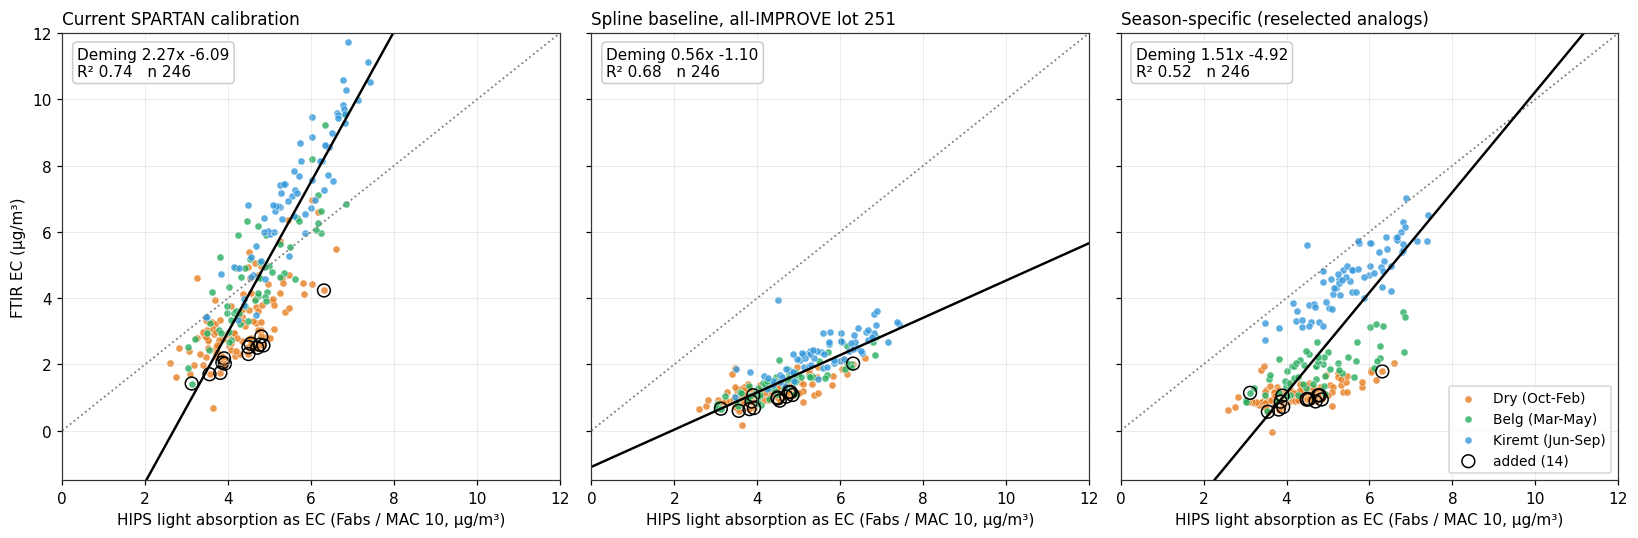

In [10]:
SEASON_COLOR = {s: v['color'] for s, v in ETHIOPIA_SEASONS.items()}
panels = [('Current SPARTAN calibration', public_ec),
          ('Spline baseline, all-IMPROVE lot 251', spl_new),
          ('Season-specific (reselected analogs)', stitched(lambda f: new_pred(f, 'reselected'), PUBLIC))]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
x = PUBLIC.Fabs_public / MAC_VALUE
lim = float(np.ceil(max(x.max(), public_ec.max())))
added_mask = ~PUBLIC.in_old
for ax, (title, p) in zip(axes, panels):
    y = p.reindex(PUBLIC.index)
    for s in SEASONS:
        m = PUBLIC.season.eq(s)
        ax.scatter(x[m], y[m], s=22, color=SEASON_COLOR[s], alpha=.8, edgecolor='white', lw=.4, label=s)
    ax.scatter(x[added_mask], y[added_mask], s=70, facecolor='none', edgecolor='black', lw=1, label='added (14)')
    st = deming(x, y)
    xs = np.array([0, lim])
    ax.plot(xs, xs, ':', color='grey', lw=1.2)
    ax.plot(xs, st['intercept'] + st['slope'] * xs, color='black', lw=1.6)
    ax.text(.03, .97, f"Deming {st['slope']:.2f}x {st['intercept']:+.2f}\nR² {st['R2']:.2f}   n {st['n']}",
            transform=ax.transAxes, va='top', fontsize=10, bbox=dict(boxstyle='round', fc='white', ec='#ccc'))
    ax.set_xlim(0, lim); ax.set_ylim(-1.5, lim)
    ax.set_title(title, loc='left', fontsize=11)
    ax.set_xlabel('HIPS light absorption as EC (Fabs / MAC 10, µg/m³)')
axes[0].set_ylabel('FTIR EC (µg/m³)')
axes[-1].legend(loc='lower right', fontsize=9)
fig.tight_layout()
fig.savefig(FIG / 'addis_public246_crossplots.png')
plt.show()

## Takeaways

1. **Spectra are not the limit.** All 246 public filters already have a spline-corrected spectrum in the frozen run the
   poster uses; the 14 that were missing from the evaluation set lacked Fabs in the in-house HIPS batch file, not spectra.
   No filter has to be fetched. More Addis data needs (a) sampling metadata for the six undated spectra (ETAD-0048,
   ETAD-0122 to 0126) and (b) the next public release plus a new spectra export for filters after 1 Mar 2026.
2. **The Addis problem is unchanged on 246 filters.** The current calibration goes from 2.30x −6.09 (R² 0.78, n 189) to
   2.27x −6.09 (R² 0.74, n 246). The lower R² comes from the 44 filters without an in-house deployed value and the 14 new
   Jan to Mar 2026 filters, not from the HIPS source (identical R² on the 188 with either Fabs).
3. **The spline-baseline all-IMPROVE lot-251 result is robust:** 0.59x −1.21 (R² 0.69) → 0.56x −1.10 (R² 0.68). Per season
   it barely moves (Dry 0.29x −0.08, Belg 0.48x −0.78, Kiremt 0.50x −0.48).
4. **Season boundaries do not change.** Every shared filter keeps its season; the additions are 13 Dry and 1 Belg, and the
   Dry season grows most (73 → 115), so the current calibration's Dry slope eases from 1.41 to 1.19.
5. **The season-specific calibrations are only partly stable.** Applying the poster's models to the 246 changes little
   (Kiremt 0.93x −0.53, R² 0.71; Belg still 0.30x +1.11, R² 0.23). Reselecting the analogs from the 246 filters leaves
   Kiremt unchanged (497 of 500 analogs shared) but moves Dry (k 17 → 7; 0.25x +0.02, R² 0.38) and especially Belg, where
   25 changed analogs and k 13 → 17 give 0.54x −0.72 with R² 0.58 instead of 0.30x +1.11 with R² 0.23. One added Belg filter
   should not change a calibration this much. The Belg and Dry season-specific numbers on the poster are fragile, and
   the k chosen by site-grouped cross-validation is the main lever. Kiremt is the robust one.
6. **Explorer counts barely move:** 254 → 257 of 3,138 spline calibrations within ±0.5 µg/m³, and 20 → 33 of those with
   slope 0.8–1.25 (reselection alone, read on the old 233: 245 and 31). All of the slope-qualified calibrations are Kiremt
   correlation analogs, before and after. The near-zero intercepts move from Belg analogs (127 → 61) to Kiremt analogs (58 → 114).
7. **Volume:** using the gallery's nominal 7.2 m³ for the 14 added filters changes no statistic by more than 0.006.

Caveats: HIPS Fabs / 10 is a comparison proxy, not an EC reference. Seasonal-analog selection and the grid rankings used the
Addis spectra only, never Addis HIPS or EC, so nothing here was tuned on the Addis outcome.